In [1]:
import warnings
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set_theme(style="whitegrid", palette="tab10")

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import lightgbm as lgb
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

In [2]:
df = sns.load_dataset("titanic")

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
df["sex"].value_counts()

sex
male      577
female    314
Name: count, dtype: int64

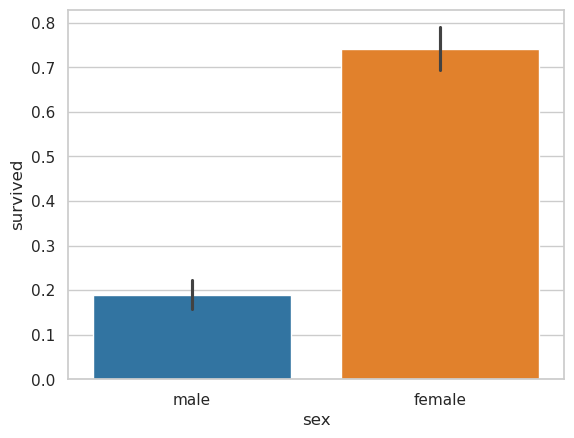

In [6]:
sns.barplot(data=df, x="sex", y="survived", hue="sex")
plt.show()

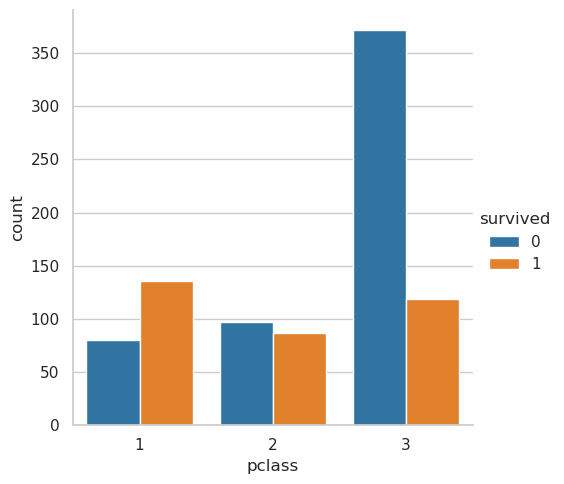

In [7]:
sns.catplot(data=df, x="pclass", hue="survived", kind="count")
plt.show()

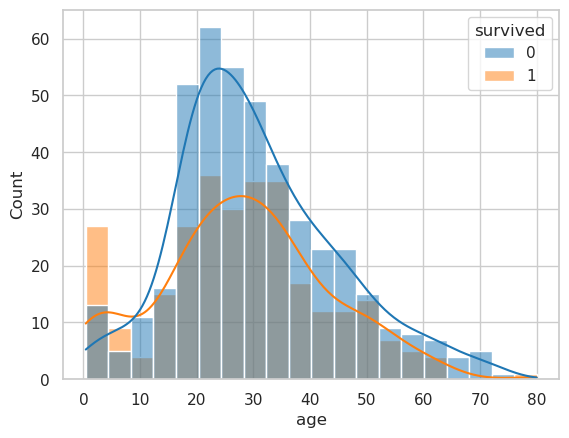

In [8]:
sns.histplot(data=df, x="age", hue="survived", kde=True)
plt.show()

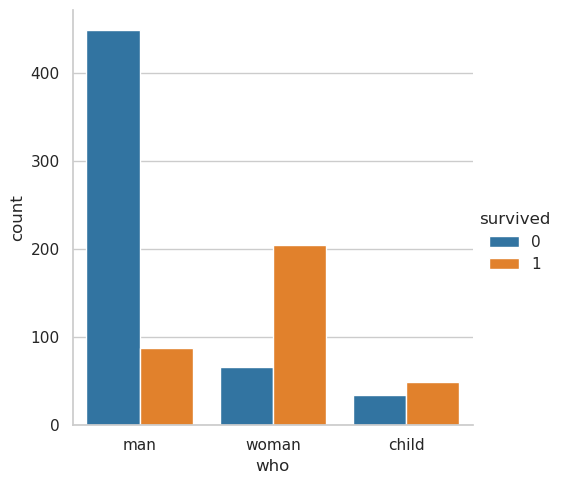

In [9]:
sns.catplot(data=df, x="who", hue="survived", kind="count")
plt.show()

In [10]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [11]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [12]:
df.drop(["embark_town", "deck", "alive", "sex"], axis=1, inplace=True)

In [13]:
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

In [14]:
df["age"] = df["age"].fillna(df["age"].median())

In [15]:
df.isnull().sum()

survived      0
pclass        0
age           0
sibsp         0
parch         0
fare          0
embarked      0
class         0
who           0
adult_male    0
alone         0
dtype: int64

In [16]:
df.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,alone
0,0,3,22.0,1,0,7.2500,S,Third,man,True,False
1,1,1,38.0,1,0,71.2833,C,First,woman,False,False
2,1,3,26.0,0,0,7.9250,S,Third,woman,False,True
3,1,1,35.0,1,0,53.1000,S,First,woman,False,False
4,0,3,35.0,0,0,8.0500,S,Third,man,True,True


In [17]:
df["embarked"].value_counts()

embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [18]:
df["class"].value_counts()

class
Third     491
First     216
Second    184
Name: count, dtype: int64

In [19]:
df["who"].value_counts()

who
man      537
woman    271
child     83
Name: count, dtype: int64

In [20]:
df["adult_male"] = df["adult_male"].astype(int)
df["alone"] = df["alone"].astype(int)

In [21]:
X = df.drop("survived", axis=1)
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=42)

In [22]:
categorical_cols = ["embarked", "who", "class"]

Preprocess = ColumnTransformer(transformers=
                               [
                                   ("cat", OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols)
                               ],
                               remainder="passthrough")

X_train = Preprocess.fit_transform(X_train)
X_test = Preprocess.transform(X_test)

In [24]:
encoded_cols = Preprocess.get_feature_names_out()
encoded_cols

array(['cat__embarked_Q', 'cat__embarked_S', 'cat__who_man',
       'cat__who_woman', 'cat__class_Second', 'cat__class_Third',
       'remainder__pclass', 'remainder__age', 'remainder__sibsp',
       'remainder__parch', 'remainder__fare', 'remainder__adult_male',
       'remainder__alone'], dtype=object)

In [206]:
X_train = pd.DataFrame(X_train, columns=encoded_cols)
X_test = pd.DataFrame(X_test, columns=encoded_cols)

In [207]:
X_train

,cat__embarked_Q,cat__embarked_S,cat__who_man,cat__who_woman,cat__class_Second,cat__class_Third,remainder__pclass,remainder__age,remainder__sibsp,remainder__parch,remainder__fare,remainder__adult_male,remainder__alone
0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,28.00,0.0,0.0,30.5000,1.0,1.0
1,0.0,1.0,1.0,0.0,0.0,1.0,3.0,25.00,0.0,0.0,7.0500,1.0,1.0
2,0.0,1.0,0.0,1.0,1.0,0.0,2.0,24.00,0.0,2.0,14.5000,0.0,0.0
3,0.0,1.0,1.0,0.0,0.0,1.0,3.0,22.00,0.0,0.0,7.5208,1.0,1.0
4,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.92,1.0,2.0,151.5500,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
663,0.0,1.0,0.0,1.0,0.0,1.0,3.0,21.00,0.0,0.0,7.6500,0.0,1.0
664,0.0,1.0,1.0,0.0,0.0,0.0,1.0,28.00,0.0,0.0,31.0000,1.0,1.0
665,0.0,1.0,1.0,0.0,0.0,1.0,3.0,41.00,2.0,0.0,14.1083,1.0,0.0
666,0.0,1.0,0.0,0.0,0.0,0.0,1.0,14.00,1.0,2.0,120.0000,0.0,0.0


In [208]:
!pip install lightgbm

In [209]:
# models = {
#     ""
# }

# pipe = Pipeline([
#     ("preprocess", Preprocess),
#     ("model", lightgbm
# ])

In [231]:
lgb_model = lgb.LGBMClassifier(verbosity=-1) # LGBMClassifier fazla bilgi yazdirdigi icin verbosity=-1 yaptik ki fazla bilgi yazdirmasin.

lgb_model.fit(X_train, y_train)
y_pred = lgb_model.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Accuracy Score:  0.8161434977578476
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

           0       0.84      0.85      0.85       134
           1       0.77      0.76      0.77        89

    accuracy                           0.82       223
   macro avg       0.81      0.81      0.81       223
weighted avg       0.82      0.82      0.82       223

------------------------------------------------------------
Confusion Matrix: 
 [[114  20]
 [ 21  68]]


In [232]:
importances = lgb_model.feature_importances_

feature_names = X_train.columns

feature_importances = pd.DataFrame(
    {
        "feature" : feature_names,
        "Importance" : importances
    }
).sort_values(by="Importance", ascending=False)

In [233]:
feature_importances # hangi kolonlarin nekadar ettki ettigini nekadar onemli oldugunu gorebiliriz.

,feature,Importance
10,remainder__fare,1150
7,remainder__age,872
1,cat__embarked_S,88
9,remainder__parch,80
2,cat__who_man,65
8,remainder__sibsp,64
5,cat__class_Third,55
12,remainder__alone,37
3,cat__who_woman,36
4,cat__class_Second,34


In [237]:
params = {
    "n_estimators" : [100, 300, 500, 100],
    "max_depth" : [3, 5, 7, -1], # None yerine -1 de koyularbilir ayni seyler.
    "learning_rate" : [0.01, 0.05, 0.1, 0.3],
    "num_leaves" : [15, 31, 63, 127], # num_leaves -> 2^(max_depth)
    "min_child_samples" : [10, 20, 30],
    "subsample" : [0.6, 0.8, 1.0],
    "colsample_bytree" : [0.6, 0.8, 1.0]
}

rscv = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=params,
    scoring="accuracy",
    verbose=1,
    cv=5,
    n_jobs=-1
)

rscv.fit(X_train, y_train)
y_pred1 = rscv.predict(X_test)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


In [241]:
def score_table(search, y_test, y_pred):
    table = []
    
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred)
    re = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    table.append({
        "Best Score" : rscv.best_score_,
        "Test Accuracy Score" : acc,
        "Precision Score" : pre,
        "Recal Score" : re,
        "F1 Score" : f1
    })

    print("Best Parameters: ", rscv.best_params_)
    print("-"*60)
    print("Classification Report: \n", classification_report(y_test, y_pred))
    print("-"*60)
    print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))
    print("\n")
    
    return pd.DataFrame(table)

score_table(rscv, y_test, y_pred1)    

Best Parameters:  {'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 100, 'min_child_samples': 30, 'max_depth': 3, 'learning_rate': 0.3, 'colsample_bytree': 0.6}
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

           0       0.85      0.87      0.86       134
           1       0.79      0.76      0.78        89

    accuracy                           0.83       223
   macro avg       0.82      0.81      0.82       223
weighted avg       0.82      0.83      0.82       223

------------------------------------------------------------
Confusion Matrix: 
 [[116  18]
 [ 21  68]]




,Best Score,Test Accuracy Score,Precision Score,Recal Score,F1 Score
0,0.842823,0.825112,0.790698,0.764045,0.777143


In [244]:
xgb = XGBClassifier(n_estimators=100)

xgb.fit(X_train, y_train)
y_pred2 = xgb.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred2))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred2))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred2))

Accuracy Score:  0.7847533632286996
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

           0       0.84      0.80      0.82       134
           1       0.72      0.76      0.74        89

    accuracy                           0.78       223
   macro avg       0.78      0.78      0.78       223
weighted avg       0.79      0.78      0.79       223

------------------------------------------------------------
Confusion Matrix: 
 [[107  27]
 [ 21  68]]


In [249]:
xgb_params = {
    "n_estimators" : [100, 300, 500, 100],
    "max_depth" : [3, 5, 7, -1], # None yerine -1 de koyularbilir ayni seyler.
    "learning_rate" : [0.01, 0.05, 0.1, 0.3],
    "colsample_bytree" : [0.6, 0.8, 1.0]
}

rscv = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_params,
    scoring="accuracy",
    verbose=1,
    n_jobs=-1
)

rscv.fit(X_train, y_train)
y_pred3 = rscv.predict(X_test)

score_table(rscv, y_test, y_pred3)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters:  {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

           0       0.85      0.87      0.86       134
           1       0.80      0.76      0.78        89

    accuracy                           0.83       223
   macro avg       0.82      0.82      0.82       223
weighted avg       0.83      0.83      0.83       223

------------------------------------------------------------
Confusion Matrix: 
 [[117  17]
 [ 21  68]]




,Best Score,Test Accuracy Score,Precision Score,Recal Score,F1 Score
0,0.830838,0.829596,0.8,0.764045,0.781609
